In [751]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

In [752]:
df = pd.read_csv("Customer Churn.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (3150, 14)


,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


In [753]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use           3150 non-null   int64  
 5   Frequency of use         3150 non-null   int64  
 6   Frequency of SMS         3150 non-null   int64  
 7   Distinct Called Numbers  3150 non-null   int64  
 8   Age Group                3150 non-null   int64  
 9   Tariff Plan              3150 non-null   int64  
 10  Status                   3150 non-null   int64  
 11  Age                      3150 non-null   int64  
 12  Customer Value           3150 non-null   float64
 13  Churn                    3150 non-null   int64  
dtypes: float64(1), int64(13)

In [754]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Call Failure,3150.0,7.627937,7.263886,0.0,1.00000,6.00,12.00000,36.00
Complains,3150.0,0.076508,0.265851,0.0,0.00000,0.00,0.00000,1.00
Subscription Length,3150.0,32.541905,8.573482,3.0,30.00000,35.00,38.00000,47.00
Charge Amount,3150.0,0.942857,1.521072,0.0,0.00000,0.00,1.00000,10.00
Seconds of Use,3150.0,4472.459683,4197.908687,0.0,1391.25000,2990.00,6478.25000,17090.00
Frequency of use,3150.0,69.460635,57.413308,0.0,27.00000,54.00,95.00000,255.00
Frequency of SMS,3150.0,73.174921,112.237560,0.0,6.00000,21.00,87.00000,522.00
Distinct Called Numbers,3150.0,23.509841,17.217337,0.0,10.00000,21.00,34.00000,97.00
Age Group,3150.0,2.826032,0.892555,1.0,2.00000,3.00,3.00000,5.00
Tariff Plan,3150.0,1.077778,0.267864,1.0,1.00000,1.00,1.00000,2.00


In [755]:
df.isnull().sum()

Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

In [756]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 300


In [757]:
print(df["Churn"].value_counts())

print("\nPercentages:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
0    2655
1     495
Name: count, dtype: int64

Percentages:
Churn
0    84.285714
1    15.714286
Name: proportion, dtype: float64


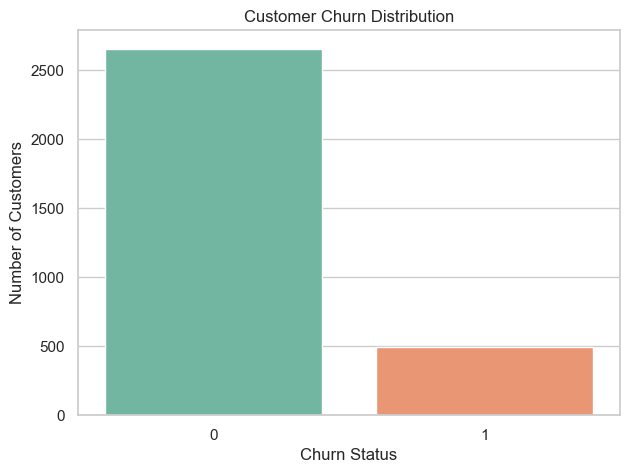

In [758]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

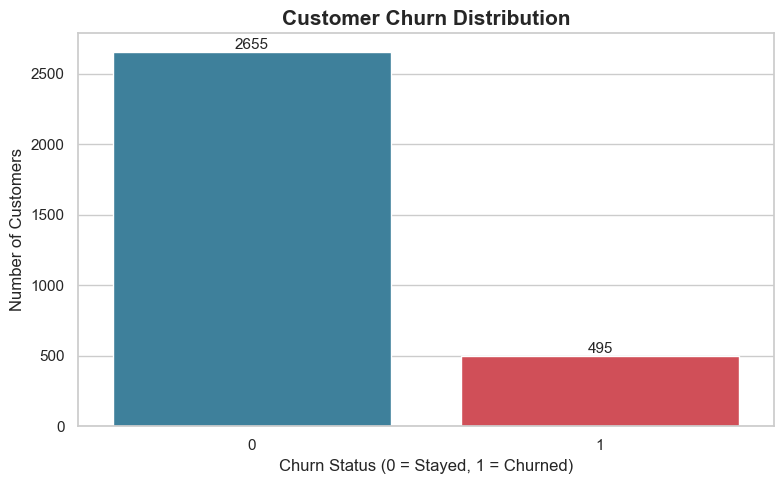

In [759]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Churn",
    hue="Churn",
    palette=["#2E86AB", "#E63946"],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fontsize=11)

plt.title(
    "Customer Churn Distribution",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Churn Status (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Complaint Impact on Customer Churn

In [760]:
complaint_analysis = (
    df.groupby("Complains")["Churn"]
    .agg(["count", "sum", "mean"])
)

complaint_analysis["Churn Rate (%)"] = (
    complaint_analysis["mean"] * 100
)

complaint_analysis

,count,sum,mean,Churn Rate (%)
Complains,,,,
0,2909,295,0.101409,10.140942
1,241,200,0.829876,82.987552


### Complaint Status vs Churn Rate

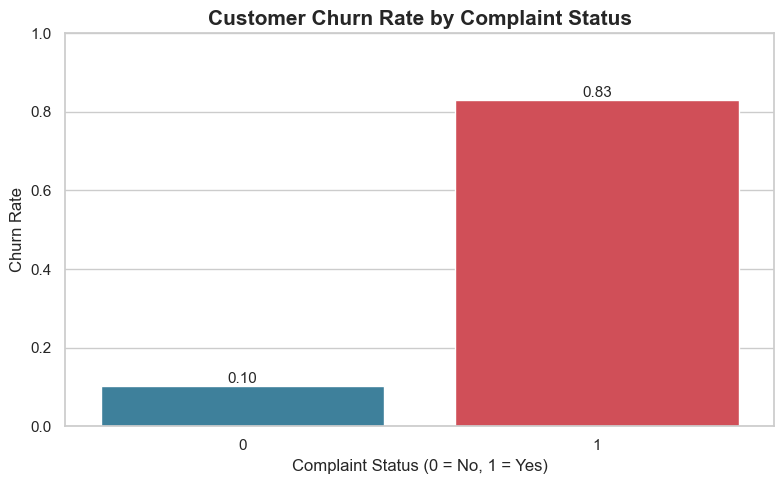

In [761]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="Complains",
    y="Churn",
    hue="Complains",
    palette=["#2E86AB", "#E63946"],
    legend=False,
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        fontsize=11
    )

plt.title(
    "Customer Churn Rate by Complaint Status",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Complaint Status (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate")

plt.ylim(0, 1)

plt.tight_layout()
plt.show()

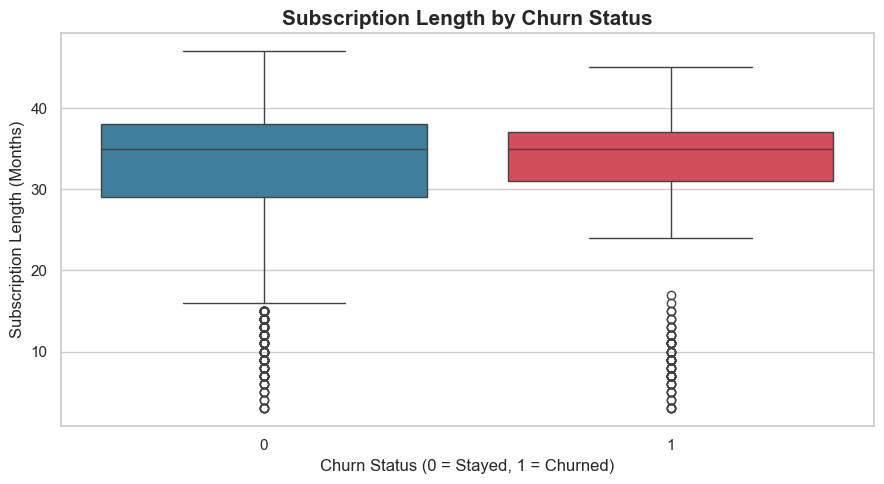

In [762]:
plt.figure(figsize=(9, 5))

ax = sns.boxplot(
    data=df,
    x="Churn",
    y="Subscription  Length",
    hue="Churn",
    palette=["#2E86AB", "#E63946"],
    legend=False
)

plt.title(
    "Subscription Length by Churn Status",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Churn Status (0 = Stayed, 1 = Churned)")
plt.ylabel("Subscription Length (Months)")

plt.tight_layout()
plt.show()

In [763]:
usage_features = [
    "Seconds of Use",
    "Frequency of use",
    "Frequency of SMS"
]

usage_analysis = (
    df.groupby("Churn")[usage_features]
    .agg(["mean", "median"])
    .round(2)
)

usage_analysis

Seconds of Use         Frequency of use        Frequency of SMS       
                mean  median             mean median             mean median
Churn                                                                       
0            5014.22  3530.0            76.98   63.0            83.87   25.0
1            1566.63  1182.0            29.13   25.0            15.80    9.0

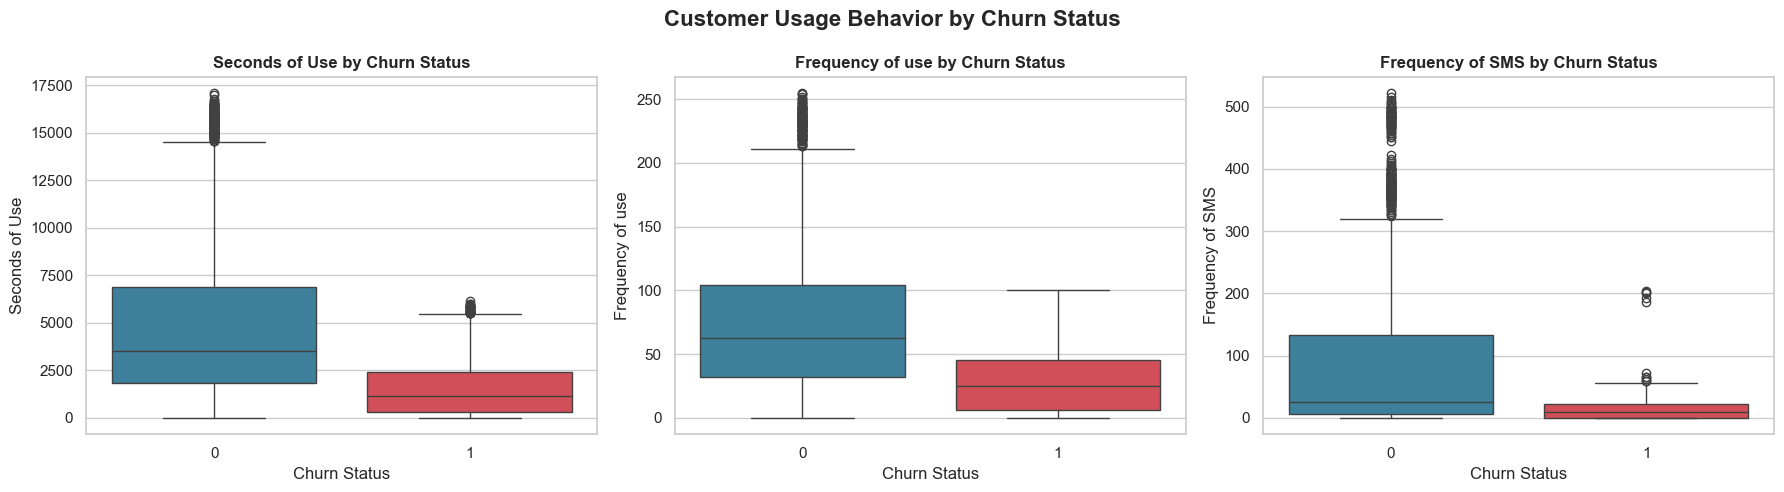

In [764]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

usage_features = [
    "Seconds of Use",
    "Frequency of use",
    "Frequency of SMS"
]

for i, feature in enumerate(usage_features):

    sns.boxplot(
        data=df,
        x="Churn",
        y=feature,
        hue="Churn",
        palette=["#2E86AB", "#E63946"],
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(
        f"{feature} by Churn Status",
        fontsize=12,
        fontweight="bold"
    )

    axes[i].set_xlabel("Churn Status")
    axes[i].set_ylabel(feature)

plt.suptitle(
    "Customer Usage Behavior by Churn Status",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

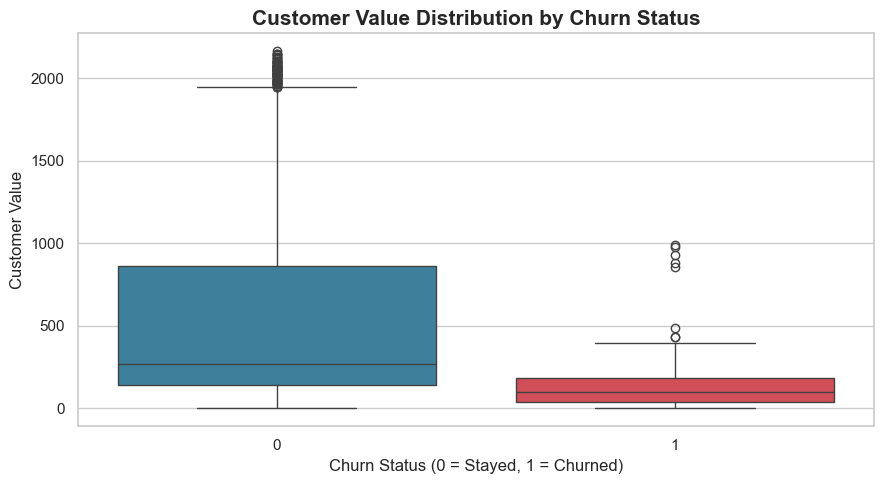

In [765]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="Customer Value",
    hue="Churn",
    palette=["#2E86AB", "#E63946"],
    legend=False
)

plt.title(
    "Customer Value Distribution by Churn Status",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Churn Status (0 = Stayed, 1 = Churned)")
plt.ylabel("Customer Value")

plt.tight_layout()
plt.show()


In [766]:
age_churn = (
    df.groupby("Age Group")["Churn"]
    .agg(["count", "sum", "mean"])
)

age_churn["Churn Rate (%)"] = (
    age_churn["mean"] * 100
)

age_churn = age_churn.round(2)

age_churn

,count,sum,mean,Churn Rate (%)
Age Group,,,,
1,123,0,0.00,0.00
2,1037,184,0.18,17.74
3,1425,230,0.16,16.14
4,395,79,0.20,20.00
5,170,2,0.01,1.18


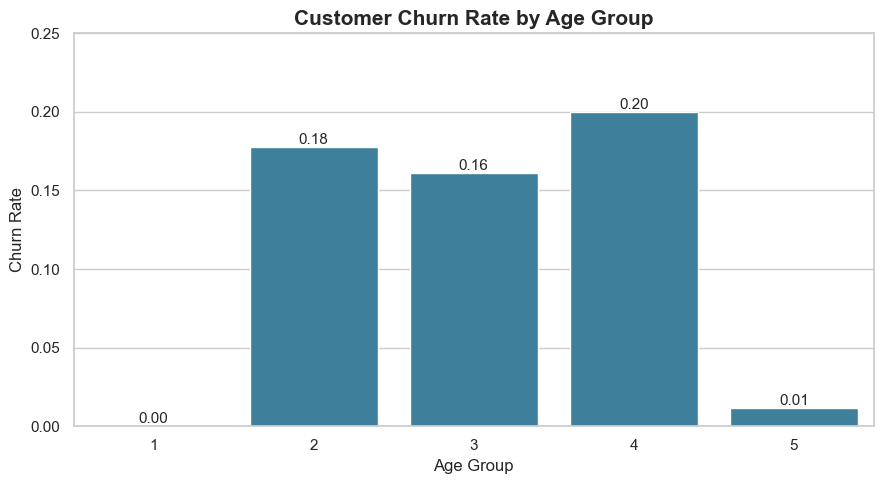

In [767]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=df,
    x="Age Group",
    y="Churn",
    color="#2E86AB",
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        fontsize=11
    )

plt.title(
    "Customer Churn Rate by Age Group",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Age Group")
plt.ylabel("Churn Rate")

plt.ylim(0, 0.25)

plt.tight_layout()
plt.show()

In [768]:
tariff_analysis = (
    df.groupby("Tariff Plan")["Churn"]
    .agg(["count", "sum", "mean"])
)

tariff_analysis["Churn Rate (%)"] = (
    tariff_analysis["mean"] * 100
)

tariff_analysis = tariff_analysis.round(2)

tariff_analysis

,count,sum,mean,Churn Rate (%)
Tariff Plan,,,,
1,2905,489,0.17,16.83
2,245,6,0.02,2.45


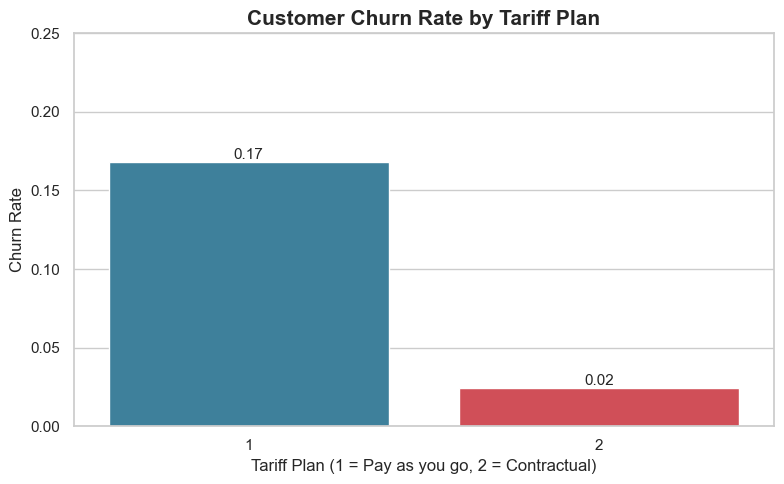

In [769]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=df,
    x="Tariff Plan",
    y="Churn",
    hue="Tariff Plan",
    palette=["#2E86AB", "#E63946"],
    legend=False,
    errorbar=None
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        fontsize=11
    )

plt.title(
    "Customer Churn Rate by Tariff Plan",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Tariff Plan (1 = Pay as you go, 2 = Contractual)")
plt.ylabel("Churn Rate")

plt.ylim(0, 0.25)

plt.tight_layout()
plt.show()

In [770]:
status_analysis = pd.crosstab(
    df["Status"],
    df["Churn"],
    margins=True
)

print("Status vs Churn Counts:")
display(status_analysis)

print("\nChurn Rate by Customer Status:")

status_churn_rate = (
    df.groupby("Status")["Churn"]
    .mean() * 100
)

display(status_churn_rate.round(2))

Status vs Churn Counts:


Churn,0,1,All
Status,,,
1,2243,125,2368
2,412,370,782
All,2655,495,3150



Churn Rate by Customer Status:


Status
1     5.28
2    47.31
Name: Churn, dtype: float64

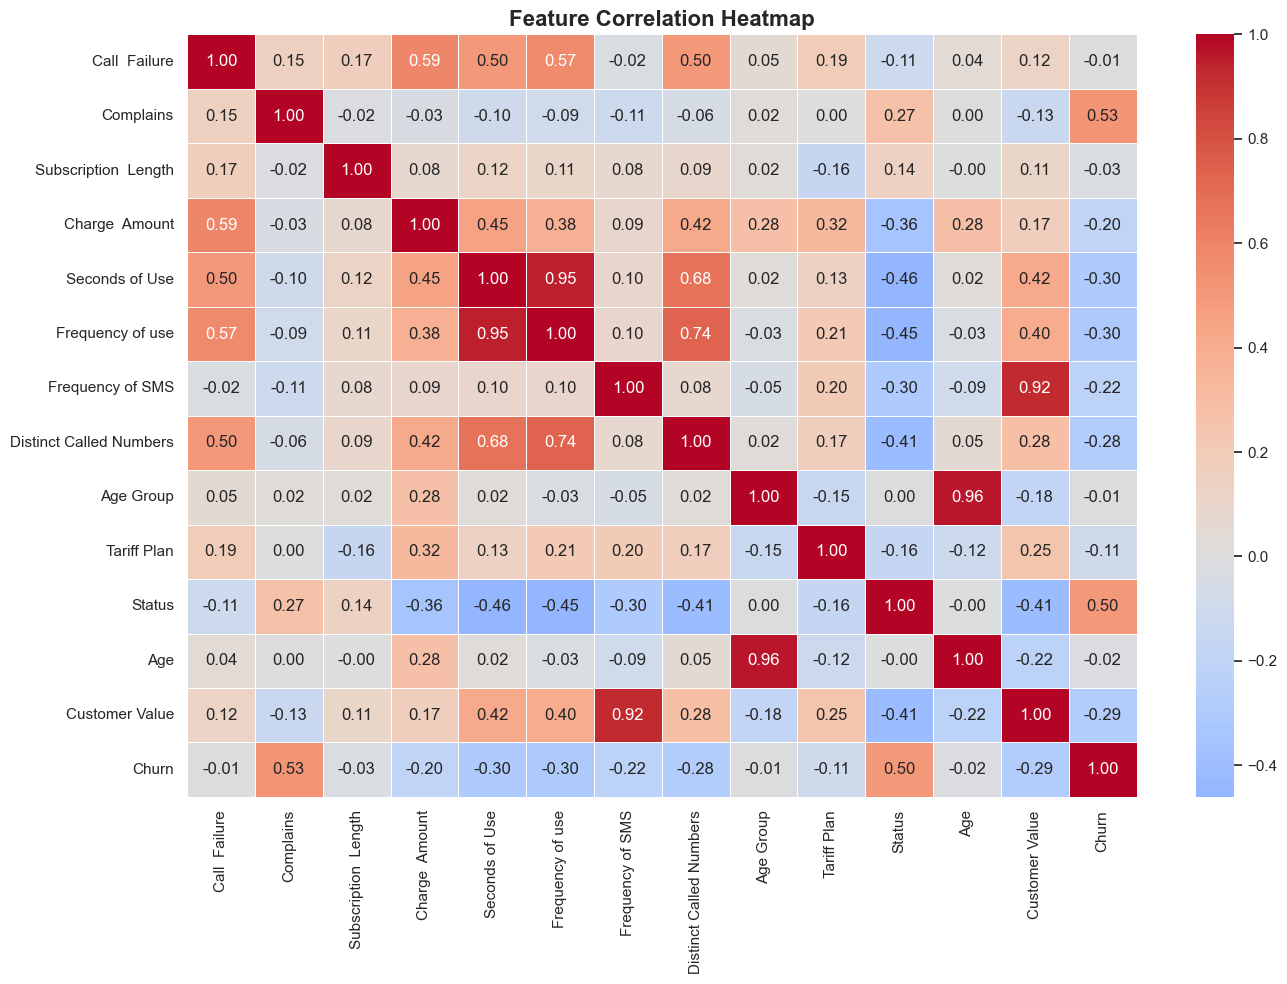

In [771]:
plt.figure(figsize=(14, 10))

correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title(
    "Feature Correlation Heatmap",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [772]:
print(" DATA QUALITY REPORT ")

# 1. Duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# 2. Missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# 3. Negative values
print("\nNegative Values:")
print((df.select_dtypes(include="number") < 0).sum())

# 4. Categorical feature values
categorical_features = [
    "Complains",
    "Age Group",
    "Tariff Plan",
    "Status",
    "Charge  Amount"
]

print("\nUnique Categorical Values:")

for col in categorical_features:
    print(f"{col}: {sorted(df[col].unique())}")

 DATA QUALITY REPORT 

Duplicate Rows:
300

Total Missing Values:
0

Negative Values:
Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64

Unique Categorical Values:
Complains: [np.int64(0), np.int64(1)]
Age Group: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Tariff Plan: [np.int64(1), np.int64(2)]
Status: [np.int64(1), np.int64(2)]
Charge  Amount: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


In [773]:
print("DUPLICATE RECORDS INVESTIGATION ")

# 1. Exact duplicate rows
duplicate_rows = df[df.duplicated(keep=False)]

print("\nTotal rows involved in duplicate groups:")
print(len(duplicate_rows))

# 2. Duplicate distribution by churn
print("\nDuplicate rows by Churn:")
print(duplicate_rows["Churn"].value_counts())

# 3. Check identical features with different targets
feature_columns = df.columns.drop("Churn")

conflicting_labels = (
    df.groupby(list(feature_columns))["Churn"]
    .nunique()
)

print("\nFeature combinations with conflicting Churn labels:")
print((conflicting_labels > 1).sum())

DUPLICATE RECORDS INVESTIGATION 

Total rows involved in duplicate groups:
465

Duplicate rows by Churn:
Churn
0    384
1     81
Name: count, dtype: int64

Feature combinations with conflicting Churn labels:
14


In [774]:
print(" CHARGE AMOUNT DISTRIBUTION ")

charge_distribution = (
    df["Charge  Amount"]
    .value_counts()
    .sort_index()
)

display(charge_distribution.to_frame(name="Customer Count"))

print("\nNumber of customers with Charge Amount = 10:")
print((df["Charge  Amount"] == 10).sum())

 CHARGE AMOUNT DISTRIBUTION 


,Customer Count
Charge Amount,
0,1768
1,617
2,395
3,199
4,76
5,30
6,11
7,14
8,19



Number of customers with Charge Amount = 10:
7


In [775]:
# Feature Engineering

# Average Usage Duration
df["Avg_Usage_Duration"] = (
    df["Seconds of Use"] /
    (df["Frequency of use"] + 1)
)

print("Feature Engineering Completed!")

print(df[[
    "Seconds of Use",
    "Frequency of use",
    "Avg_Usage_Duration"
]].head())

Feature Engineering Completed!
   Seconds of Use  Frequency of use  Avg_Usage_Duration
0            4370                71           60.694444
1             318                 5           53.000000
2            2453                60           40.213115
3            4198                66           62.656716
4            2393                58           40.559322


In [776]:
# Duplicate Analysis

print("Exact Duplicate Rows:")
print(df.duplicated().sum())

print("\nDuplicate Feature Rows:")
print(df.drop(columns=["Churn"]).duplicated().sum())

print("\nDataset Shape:")
print(df.shape)

Exact Duplicate Rows:
300

Duplicate Feature Rows:
314

Dataset Shape:
(3150, 15)


In [777]:
# Remove Exact Duplicates

print("Dataset Shape Before:", df.shape)

df = df.drop_duplicates().reset_index(drop=True)

print("Dataset Shape After:", df.shape)
print("Remaining Duplicates:", df.duplicated().sum())

Dataset Shape Before: (3150, 15)
Dataset Shape After: (2850, 15)
Remaining Duplicates: 0


In [778]:
# Handle Conflicting Duplicate Features

feature_columns = df.drop(columns=["Churn"]).columns.tolist()

conflicting_rows = df.duplicated(
    subset=feature_columns,
    keep=False
)

print("Conflicting Rows:", conflicting_rows.sum())

df = df.loc[~conflicting_rows].copy()

print("Dataset Shape After Cleaning:", df.shape)

Conflicting Rows: 28
Dataset Shape After Cleaning: (2822, 15)


 Data Preprocessing & Feature Engineering

In [779]:
#Define Features and Target

X = df.drop(columns=["Churn"])

y = df["Churn"]

print("Features shape:", X.shape)

print("Target shape:", y.shape)

print("\nTarget distribution:")

print(y.value_counts())

print("\nFeature columns:")

print(X.columns.tolist())

Features shape: (2822, 14)
Target shape: (2822,)

Target distribution:
Churn
0    2390
1     432
Name: count, dtype: int64

Feature columns:
['Call  Failure', 'Complains', 'Subscription  Length', 'Charge  Amount', 'Seconds of Use', 'Frequency of use', 'Frequency of SMS', 'Distinct Called Numbers', 'Age Group', 'Tariff Plan', 'Status', 'Age', 'Customer Value', 'Avg_Usage_Duration']


In [780]:
# Train/Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (2257, 14)
Testing Features: (565, 14)

Training Target: (2257,)
Testing Target: (565,)


In [781]:
# Check Duplicate Features Between Train and Test

train_features = X_train.drop_duplicates()
test_features = X_test.drop_duplicates()

overlap = train_features.merge(
    test_features,
    how="inner"
)

print("Overlapping Feature Rows:", len(overlap))

Overlapping Feature Rows: 0


In [782]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [783]:
# Logistic Regression with Cross Validation

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Define Model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

# Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation Metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

# Cross Validation
logistic_cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Display Results
print("Logistic Regression Cross Validation Results")

for metric in scoring:
    scores = logistic_cv_results["test_" + metric]

    print(
        metric,
        ":",
        round(scores.mean(), 4)
    )

Logistic Regression Cross Validation Results
accuracy : 0.8343
precision : 0.4778
recall : 0.8641
f1 : 0.6152
roc_auc : 0.929
pr_auc : 0.7454


In [784]:
#RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Define Random Forest Pipeline
random_forest_pipeline = Pipeline(steps=[
    ("model", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Cross Validation
random_forest_cv_results = cross_validate(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Display Results
print("=== Random Forest — 5-Fold Cross-Validation ===")

for metric in scoring:
    scores = random_forest_cv_results[f"test_{metric}"]

    print(
        f"{metric.upper()}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

=== Random Forest — 5-Fold Cross-Validation ===
ACCURACY: 0.9637 ± 0.0041
PRECISION: 0.9431 ± 0.0131
RECALL: 0.8122 ± 0.0253
F1: 0.8725 ± 0.0155
ROC_AUC: 0.9904 ± 0.0027
PR_AUC: 0.9561 ± 0.0094


In [785]:
# Gradient Boosting Model

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Gradient Boosting Pipeline
gradient_boosting_pipeline = Pipeline(
    steps=[
        ("model", GradientBoostingClassifier(
            n_estimators=150,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        ))
    ]
)

# Cross Validation
gradient_boosting_cv_results = cross_validate(
    gradient_boosting_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Display Results
print("=== Gradient Boosting — 5-Fold Cross-Validation ===")

for metric in scoring:
    scores = gradient_boosting_cv_results[f"test_{metric}"]

    print(
        f"{metric.upper()}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

=== Gradient Boosting — 5-Fold Cross-Validation ===
ACCURACY: 0.9522 ± 0.0053
PRECISION: 0.9083 ± 0.0291
RECALL: 0.7659 ± 0.0267
F1: 0.8306 ± 0.0196
ROC_AUC: 0.9821 ± 0.0066
PR_AUC: 0.9273 ± 0.0141


In [786]:
# Status Feature Ablation Study

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Remove Status from training features
X_train_no_status = X_train.drop(columns=["Status"])

# Random Forest Pipeline without Status
rf_no_status_pipeline = Pipeline(steps=[
    ("model", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

# Cross Validation
rf_no_status_results = cross_validate(
    rf_no_status_pipeline,
    X_train_no_status,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Compare Results
print("=== Random Forest: With vs Without Status ===")

for metric in scoring:
    with_status = random_forest_cv_results[f"test_{metric}"].mean()
    without_status = rf_no_status_results[f"test_{metric}"].mean()

    print(
        f"{metric.upper()} | "
        f"With Status: {with_status:.4f} | "
        f"Without Status: {without_status:.4f}"
    )

=== Random Forest: With vs Without Status ===
ACCURACY | With Status: 0.9637 | Without Status: 0.9486
PRECISION | With Status: 0.9431 | Without Status: 0.9114
RECALL | With Status: 0.8122 | Without Status: 0.7371
F1 | With Status: 0.8725 | Without Status: 0.8139
ROC_AUC | With Status: 0.9904 | Without Status: 0.9864
PR_AUC | With Status: 0.9561 | Without Status: 0.9255


In [787]:
# Random Forest Hyperparameter Tuning

from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": ["sqrt", "log2"]
}

rf_random_search = RandomizedSearchCV(
    estimator=rf_no_status_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

rf_random_search.fit(
    X_train_no_status,
    y_train
)

print("\n=== Best Hyperparameters ===")
print(rf_random_search.best_params_)

print("\n=== Best Cross-Validation F1-score ===")
print(round(rf_random_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits

=== Best Hyperparameters ===
{'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 30}

=== Best Cross-Validation F1-score ===
0.8618


In [788]:
# Tuned Random Forest Cross-Validation

from sklearn.model_selection import cross_validate

# Best Tuned Random Forest Pipeline
tuned_rf_pipeline = rf_random_search.best_estimator_

# Cross Validation
tuned_rf_cv_results = cross_validate(
    tuned_rf_pipeline,
    X_train_no_status,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Display Results
print("=== Tuned Random Forest — 5-Fold CV ===")

for metric in scoring:
    scores = tuned_rf_cv_results[f"test_{metric}"]

    print(
        f"{metric.upper()}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

=== Tuned Random Forest — 5-Fold CV ===
ACCURACY: 0.9592 ± 0.0085
PRECISION: 0.8948 ± 0.0284
RECALL: 0.8324 ± 0.0463
F1: 0.8618 ± 0.0308
ROC_AUC: 0.9860 ± 0.0032
PR_AUC: 0.9234 ± 0.0148


In [789]:
# Final Model Evaluation on Test Set

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Remove Status from test features
X_test_no_status = X_test.drop(columns=["Status"])

# Best model was already fitted by RandomizedSearchCV
final_model = rf_random_search.best_estimator_

# Predictions
y_pred = final_model.predict(X_test_no_status)

# Predicted churn probabilities
y_proba = final_model.predict_proba(X_test_no_status)[:, 1]

print("=== FINAL TEST SET EVALUATION ===")

print("\nPrecision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("PR-AUC:", round(average_precision_score(y_test, y_proba), 4))

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred))

print("\n=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

=== FINAL TEST SET EVALUATION ===

Precision: 0.8353
Recall: 0.8256
F1-score: 0.8304
PR-AUC: 0.9133

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       479
           1       0.84      0.83      0.83        86

    accuracy                           0.95       565
   macro avg       0.90      0.90      0.90       565
weighted avg       0.95      0.95      0.95       565


=== Confusion Matrix ===
[[465  14]
 [ 15  71]]


In [790]:
#  Save Final Model with Joblib

import joblib
from pathlib import Path

# Create models directory if it doesn't exist
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save the complete trained pipeline
model_path = models_dir / "churnguard_pipeline.joblib"

joblib.dump(final_model, model_path)

print("Model saved successfully!")
print("Model path:", model_path.resolve())
print("Model file size (KB):", round(model_path.stat().st_size / 1024, 2))

Model saved successfully!
Model path: C:\Users\RTC\OneDrive\Desktop\MACHINE\models\churnguard_pipeline.joblib
Model file size (KB): 5109.6
